In [1]:
import os
from huggingface_hub import login

try:
    from kaggle_secrets import UserSecretsClient
    secrets = UserSecretsClient()
    HF_TOKEN = secrets.get_secret("HF")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN", "")

os.environ["HF_TOKEN"] = HF_TOKEN
if HF_TOKEN:
    login(token=HF_TOKEN)
    print("Hugging Face login successful.")
else:
    print("HF_TOKEN not found in secrets/environment. Continuing unauthenticated.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0" 

import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for idx in range(torch.cuda.device_count()):
    print(f"GPU {idx}:", torch.cuda.get_device_name(idx))

CUDA available: True
GPU count: 1
GPU 0: Tesla T4


In [3]:
%%writefile attention.py
import math
from typing import Optional, Tuple
import torch
import torch.nn as nn
import torch.nn.functional as F


class CausalSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, max_seq_len: int, dropout: float = 0, attention_scale: float = None,
                 use_rope: bool = True, rope_base: float = 10000.0):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be evenly divisible by n_heads"
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.attention_scale = (1.0 / math.sqrt(self.d_head)) if attention_scale is None else float(attention_scale)

        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.gate_proj = nn.Linear(d_model, d_model, bias=False)

        self.use_rope = use_rope
        if use_rope:
            assert self.d_head % 2 == 0, "RoPE needs an even head dimension"
            inv_freq = 1.0 / (rope_base ** (torch.arange(0, self.d_head, 2, dtype=torch.float32) / self.d_head))
            pos_steps = torch.arange(max_seq_len, dtype=torch.float32)
            angles = torch.outer(pos_steps, inv_freq)
            self.register_buffer("rope_cos", torch.cos(angles), persistent=False)
            self.register_buffer("rope_sin", torch.sin(angles), persistent=False)

        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        self.register_buffer(
            "causal_mask",
            torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool)),
            persistent=False
        )

    def _apply_rope(self, x: torch.Tensor, start: int) -> torch.Tensor:
        seq_len = x.size(2)
        cos = self.rope_cos[start:start + seq_len].float()
        sin = self.rope_sin[start:start + seq_len].float()
        half_dim = self.d_head // 2
        x1, x2 = x[..., :half_dim].float(), x[..., half_dim:].float()
        rotated = torch.cat((x1 * cos - x2 * sin, x1 * sin + x2 * cos), dim=-1)
        return rotated.to(x.dtype)

    def forward(
        self,
        x: torch.Tensor,
        past_kv: Optional[Tuple[torch.Tensor, torch.Tensor]] = None,
        use_cache: bool = False,
        key_padding_mask: Optional[torch.Tensor] = None,
    ):
        bsz, seq_len, dim = x.shape

        q = self.q_proj(x).view(bsz, seq_len, self.n_heads, self.d_head).transpose(1, 2)
        k = self.k_proj(x).view(bsz, seq_len, self.n_heads, self.d_head).transpose(1, 2)
        v = self.v_proj(x).view(bsz, seq_len, self.n_heads, self.d_head).transpose(1, 2)

        offset = 0 if past_kv is None else past_kv[0].size(2)

        if self.use_rope:
            q = self._apply_rope(q, offset)
            k = self._apply_rope(k, offset)

        if past_kv is not None:
            k = torch.cat([past_kv[0], k], dim=2)
            v = torch.cat([past_kv[1], v], dim=2)
        cached_kv = (k, v) if use_cache else None

        if key_padding_mask is None and offset == 0:
            out = F.scaled_dot_product_attention(
                q, k, v,
                dropout_p=self.attn_dropout.p if self.training else 0.0,
                is_causal=True,
                scale=self.attention_scale,
            )
        else:
            total_len = offset + seq_len
            scores = (q @ k.transpose(-2, -1)) * self.attention_scale
            mask = self.causal_mask[offset:total_len, :total_len]
            if key_padding_mask is not None:
                mask = mask.unsqueeze(0) & key_padding_mask.to(torch.bool).unsqueeze(1)
                mask = mask | ~mask.any(dim=-1, keepdim=True)
                mask = mask.unsqueeze(1)
            scores = scores.masked_fill(~mask, float("-inf"))
            probs = self.attn_dropout(F.softmax(scores, dim=-1))
            out = probs @ v

        out = out.transpose(1, 2).contiguous().view(bsz, seq_len, dim)
        out = out * torch.sigmoid(self.gate_proj(x))
        out = self.resid_dropout(self.out_proj(out))

        if use_cache:
            return out, cached_kv
        return out

Writing attention.py


In [4]:
%%writefile model_arch.py
import math
from dataclasses import dataclass
from typing import Optional, List, Tuple
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers.utils import ModelOutput
from attention import CausalSelfAttention


@dataclass
class LMConfig:
    vocab_size: int
    d_model: int = 560
    n_layers: int = 8
    n_heads: int = 8
    d_ff: int = 2240
    max_seq_len: int = 1024
    dropout: float = 0
    pos_emb_type: str = "rope"
    attention_scale: float = None
    norm_first: bool = True
    bos_token_id: int = None
    eos_token_id: int = None


@dataclass
class CausalLMOutput(ModelOutput):
    loss: Optional[torch.Tensor] = None
    logits: Optional[torch.Tensor] = None
    past_key_values: Optional[List[Tuple[torch.Tensor, torch.Tensor]]] = None


def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    pos = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
    scale = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
    pe = torch.zeros(max_len, d_model, dtype=torch.float32)
    pe[:, 0::2] = torch.sin(pos * scale)
    pe[:, 1::2] = torch.cos(pos * scale)
    return pe


class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class Block(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.norm_first = getattr(cfg, 'norm_first', True)
        self.ln1 = nn.LayerNorm(cfg.d_model)
        self.attn = CausalSelfAttention(
            d_model=cfg.d_model,
            n_heads=cfg.n_heads,
            max_seq_len=cfg.max_seq_len,
            dropout=cfg.dropout,
            attention_scale=cfg.attention_scale,
            use_rope=(cfg.pos_emb_type == "rope")
        )
        self.ln2 = nn.LayerNorm(cfg.d_model)
        self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)

    def forward(self, x: torch.Tensor, past_kv=None, use_cache: bool = False, key_padding_mask=None):
        if self.norm_first:
            attn_out = self.attn(self.ln1(x), past_kv=past_kv, use_cache=use_cache, key_padding_mask=key_padding_mask)
            if use_cache:
                attn_out, present = attn_out
            x = x + attn_out
            x = x + self.ffn(self.ln2(x))
        else:
            attn_out = self.attn(x, past_kv=past_kv, use_cache=use_cache, key_padding_mask=key_padding_mask)
            if use_cache:
                attn_out, present = attn_out
            x = self.ln1(x + attn_out)
            x = self.ln2(x + self.ffn(x))
        if use_cache:
            return x, present
        return x


class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)

        if cfg.pos_emb_type == "sinusoidal":
            pe = sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model)
            self.register_buffer("pos_emb", pe, persistent=False)

        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
        elif isinstance(module, nn.LayerNorm):
            torch.nn.init.ones_(module.weight)
            torch.nn.init.zeros_(module.bias)

    def forward(self, input_ids: torch.Tensor = None, labels: torch.Tensor = None, idx: torch.Tensor = None,
                past_key_values: Optional[List[Tuple[torch.Tensor, torch.Tensor]]] = None,
                use_cache: bool = False,
                attention_mask: Optional[torch.Tensor] = None,
                last_token_only: bool = False):
        if idx is None:
            idx = input_ids
        assert idx is not None, "Either input_ids or idx must be provided"

        bsz, seq_len = idx.shape
        past_len = 0 if past_key_values is None else past_key_values[0][0].size(2)
        assert past_len + seq_len <= self.cfg.max_seq_len,             f"Seq length {past_len + seq_len} exceeds max sequence length {self.cfg.max_seq_len}"

        x = self.tok_emb(idx)
        if self.cfg.pos_emb_type == "sinusoidal":
            if attention_mask is None:
                x = x + self.pos_emb[past_len:past_len + seq_len]
            else:
                pos_ids = (attention_mask.long().cumsum(dim=-1) - 1).clamp(min=0)[:, -seq_len:]
                x = x + self.pos_emb[pos_ids]

        presents = [] if use_cache else None
        for i, block in enumerate(self.blocks):
            past_kv = None if past_key_values is None else past_key_values[i]
            if use_cache:
                x, present = block(x, past_kv=past_kv, use_cache=True, key_padding_mask=attention_mask)
                presents.append(present)
            else:
                x = block(x, past_kv=past_kv, key_padding_mask=attention_mask)

        if last_token_only:
            x = x[:, -1:, :]
        x = self.ln_f(x)
        logits = self.head(x)

        if labels is not None:
            shift_logits = logits[:, :-1, :].contiguous().view(-1, self.cfg.vocab_size)
            shift_labels = labels[:, 1:].contiguous().view(-1)
            loss = F.cross_entropy(shift_logits, shift_labels, ignore_index=-100)
            return CausalLMOutput(loss=loss, logits=logits, past_key_values=presents)

        if use_cache:
            return logits, presents
        return logits

    @torch.no_grad()
    def generate(self, idx: torch.Tensor, max_new_tokens: int, temperature: float = 1.0, top_p: float = 1.0, eos_token_id: int = None, attention_mask: torch.Tensor = None,
                 stop_check=None, check_every: int = 16) -> torch.Tensor:
        was_training = self.training
        self.eval()

        bsz = idx.size(0)
        if attention_mask is not None:
            attention_mask = attention_mask.to(device=idx.device, dtype=torch.bool)
        finished = torch.zeros(bsz, dtype=torch.bool, device=idx.device)

        prompt_len = idx.size(1)
        past_key_values = None
        cond_mask = None
        for step in range(max_new_tokens):
            if past_key_values is None or past_key_values[0][0].size(2) + 1 > self.cfg.max_seq_len:
                past_key_values = None
                idx_cond = idx[:, -self.cfg.max_seq_len:]
                cond_mask = None if attention_mask is None else attention_mask[:, -self.cfg.max_seq_len:]
            else:
                idx_cond = idx[:, -1:]

            logits, past_key_values = self(idx_cond, past_key_values=past_key_values, use_cache=True,
                                           attention_mask=cond_mask, last_token_only=True)
            logits = logits[:, -1, :] / max(temperature, 1e-5)

            if top_p < 1.0:
                sorted_logits, sorted_indices = torch.sort(logits, descending=True)
                cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
                sorted_indices_to_remove = cumulative_probs > top_p
                sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
                sorted_indices_to_remove[..., 0] = 0
                indices_to_remove = sorted_indices_to_remove.scatter(1, sorted_indices, sorted_indices_to_remove)
                logits = logits.masked_fill(indices_to_remove, float('-inf'))

            probs = F.softmax(logits, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)

            if eos_token_id is not None:
                next_token = torch.where(finished.unsqueeze(1), torch.full_like(next_token, eos_token_id), next_token)
                finished = finished | (next_token.squeeze(1) == eos_token_id)

            idx = torch.cat((idx, next_token), dim=1)
            if attention_mask is not None:
                ones = torch.ones(bsz, 1, dtype=torch.bool, device=idx.device)
                attention_mask = torch.cat((attention_mask, ones), dim=1)
                cond_mask = torch.cat((cond_mask, ones), dim=1)

            if eos_token_id is not None and finished.all():
                break

            if stop_check is not None and (step + 1) % check_every == 0:
                satisfied = torch.as_tensor(stop_check(idx[:, prompt_len:]), dtype=torch.bool, device=idx.device)
                if (satisfied | finished).all():
                    break

        if was_training:
            self.train()
        return idx

    @staticmethod
    def _repeated_ngram_tokens(seq, n):
        if len(seq) < n - 1:
            return []
        prefix = tuple(seq[len(seq) - (n - 1):])
        banned = []
        for i in range(len(seq) - n + 1):
            if tuple(seq[i:i + n - 1]) == prefix:
                banned.append(seq[i + n - 1])
        return banned

    @torch.no_grad()
    def generate_beam(self, idx: torch.Tensor, max_new_tokens: int, num_beams: int = 4, temperature: float = 1.0,
                      attention_mask: torch.Tensor = None, no_repeat_ngram_size: int = 0, banned_token_ids=None,
                      stop_check=None, check_every: int = 16) -> torch.Tensor:
        was_training = self.training
        self.eval()

        bsz, seq_len = idx.shape
        nb = num_beams
        device = idx.device
        max_new_tokens = min(max_new_tokens, self.cfg.max_seq_len - seq_len)

        if attention_mask is None:
            attention_mask = torch.ones(bsz, seq_len, dtype=torch.bool, device=device)
        attention_mask = attention_mask.to(device=device, dtype=torch.bool)

        logits, past = self(idx, use_cache=True, attention_mask=attention_mask, last_token_only=True)
        past = [(k.repeat_interleave(nb, dim=0), v.repeat_interleave(nb, dim=0)) for k, v in past]
        mask = attention_mask.repeat_interleave(nb, dim=0)
        next_logits = logits[:, -1, :].repeat_interleave(nb, dim=0)

        beam_scores = torch.zeros(bsz, nb, device=device)
        beam_scores[:, 1:] = float("-inf")
        gen = torch.empty(bsz * nb, 0, dtype=torch.long, device=device)
        row_offset = (torch.arange(bsz, device=device) * nb).unsqueeze(1)

        for step in range(max_new_tokens):
            if step > 0:
                mask = torch.cat([mask, torch.ones(bsz * nb, 1, dtype=torch.bool, device=device)], dim=1)
                out, past = self(gen[:, -1:], past_key_values=past, use_cache=True,
                                 attention_mask=mask, last_token_only=True)
                next_logits = out[:, -1, :]

            log_probs = F.log_softmax(next_logits.float() / max(temperature, 1e-5), dim=-1)

            if banned_token_ids:
                log_probs[:, banned_token_ids] = float("-inf")

            if no_repeat_ngram_size > 0 and gen.size(1) >= no_repeat_ngram_size - 1:
                for r, seq in enumerate(gen.tolist()):
                    bad = self._repeated_ngram_tokens(seq, no_repeat_ngram_size)
                    if bad:
                        log_probs[r, bad] = float("-inf")

            vocab = log_probs.size(-1)
            scores = (beam_scores.view(-1, 1) + log_probs).reshape(bsz, nb * vocab)
            beam_scores, top_idx = scores.topk(nb, dim=-1)

            src_beam = (top_idx // vocab + row_offset).view(-1)
            next_tok = (top_idx % vocab).view(-1, 1)

            gen = torch.cat([gen[src_beam], next_tok], dim=1)
            past = [(k[src_beam], v[src_beam]) for k, v in past]

            if stop_check is not None and (step + 1) % check_every == 0:
                best_so_far = gen.view(bsz, nb, -1)[:, 0]
                satisfied = torch.as_tensor(stop_check(best_so_far), dtype=torch.bool)
                if satisfied.all():
                    break

        best = gen.view(bsz, nb, -1)[:, 0]
        if was_training:
            self.train()
        return torch.cat([idx, best], dim=1)

Writing model_arch.py


In [5]:
import os, json, time, math, random, zipfile
import numpy as np
import torch

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

SMOKE_TEST = False

TRAIN_FRACTION = 0.50
SUBSAMPLE_SEED = 42

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
PHASE1_REPO = "Granth2/cs781-phase1-Submission-9"
PHASE1_WEIGHTS = "pytorch_model.bin"
TRAIN_FILE = "Phase_4_CJPE/Train/train.json"
DEV_FILE = "Phase_4_CJPE/Train/dev.json"
TEST_FILE = "Phase_4_CJPE/Test/test.json"

OUTPUT_DIR = "/kaggle/working/cs781_phase4"
CACHE_DIR = os.path.join(OUTPUT_DIR, "token_cache")
RUN_TAG = "smoke" if SMOKE_TEST else f"frac{TRAIN_FRACTION:g}"
CKPT_DIR = os.path.join(OUTPUT_DIR, f"checkpoints_{RUN_TAG}")
SUB_DIR = os.path.join(OUTPUT_DIR, "submission")
for folder in (OUTPUT_DIR, CACHE_DIR, CKPT_DIR, SUB_DIR):
    os.makedirs(folder, exist_ok=True)

HF_TOKEN_ARG = HF_TOKEN if (HF_TOKEN and str(HF_TOKEN).strip()) else None

MODEL_CONTEXT_LENGTH = 1024
N_EMBD, N_LAYER, N_HEAD = 768, 12, 12

CHUNK_LEN = 512
CHUNK_OVERLAP = 64
MAX_CHUNKS = 16
BATCH_SIZE = 4
GRAD_ACCUM = 4

EPOCHS = 3
LR_BACKBONE = 3e-5
LR_HEAD = 5e-4
WEIGHT_DECAY = 0.01
LOG_EVERY = 20

MAX_TRAIN_DOCS = MAX_DEV_DOCS = MAX_TEST_DOCS = None
if SMOKE_TEST:
    MAX_TRAIN_DOCS, MAX_DEV_DOCS, MAX_TEST_DOCS = 64, 32, 32
    TRAIN_FRACTION = 1.0
    EPOCHS = 1
    LOG_EVERY = 2
    print("SMOKE TEST MODE - tiny subset, 1 epoch. Do not submit these predictions.")

print(f"Configuration loaded. run tag = {RUN_TAG}, train fraction = {TRAIN_FRACTION:g}")

Configuration loaded. run tag = frac0.5, train fraction = 0.5


In [6]:
import os
import json
from transformers import PreTrainedTokenizer
from huggingface_hub import hf_hub_download


class MyCustomTokenizer(PreTrainedTokenizer):
    END_OF_WORD = "</w>"

    def __init__(self, vocab_file, merges_file, pad_token="<pad>", unk_token="<unk>",
                 bos_token="<s>", eos_token="</s>", **kwargs):
        with open(vocab_file, "r", encoding="utf-8") as f:
            self.vocab = json.load(f)
        self.id_to_token = {i: t for t, i in self.vocab.items()}

        self.byte_to_char = self._build_byte_to_char()
        self.char_to_byte = {c: b for b, c in self.byte_to_char.items()}

        self.merge_ranks = self._load_merges(merges_file)
        self.word_cache = {}

        kwargs.setdefault("clean_up_tokenization_spaces", False)
        super().__init__(
            pad_token=pad_token,
            unk_token=unk_token,
            bos_token=bos_token,
            eos_token=eos_token,
            **kwargs
        )

    @staticmethod
    def _build_byte_to_char():
        printable = (list(range(ord("!"), ord("~") + 1))
                     + list(range(ord("¡"), ord("¬") + 1))
                     + list(range(ord("®"), ord("ÿ") + 1)))
        byte_values = printable[:]
        char_codes = printable[:]
        extra = 0
        for b in range(256):
            if b not in printable:
                byte_values.append(b)
                char_codes.append(256 + extra)
                extra += 1
        return {b: chr(c) for b, c in zip(byte_values, char_codes)}

    def _byte_ids_to_symbol(self, text):
        symbol = ""
        for part in text.split("+"):
            if part == self.END_OF_WORD:
                symbol += part
            else:
                symbol += self.byte_to_char[int(part[2:])]
        return symbol

    def _load_merges(self, merges_file):
        pairs = []
        with open(merges_file, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if not line or line.startswith("#version"):
                    continue
                parts = line.split(" ")
                if len(parts) == 2:
                    pairs.append((parts[0], parts[1]))

        is_byte_ids = len(pairs) > 0 and pairs[0][0].startswith("b:")

        merge_ranks = {}
        for left, right in pairs:
            if is_byte_ids:
                left = self._byte_ids_to_symbol(left)
                right = self._byte_ids_to_symbol(right)
            merge_ranks[(left, right)] = len(merge_ranks)
        return merge_ranks

    @property
    def vocab_size(self):
        return len(self.vocab)

    def get_vocab(self):
        return self.vocab

    def _split_word(self, word):
        if word in self.word_cache:
            return self.word_cache[word]

        symbols = [self.byte_to_char[b] for b in word.encode("utf-8")] + [self.END_OF_WORD]

        while len(symbols) > 1:
            pairs = [(symbols[i], symbols[i + 1]) for i in range(len(symbols) - 1)]
            valid_pairs = [p for p in pairs if p in self.merge_ranks]
            if not valid_pairs:
                break

            best_pair = min(valid_pairs, key=lambda p: self.merge_ranks[p])

            merged = []
            i = 0
            while i < len(symbols):
                if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == best_pair:
                    merged.append(best_pair[0] + best_pair[1])
                    i += 2
                else:
                    merged.append(symbols[i])
                    i += 1
            symbols = merged

        tokens = [s if s in self.vocab else self.unk_token for s in symbols]

        if len(self.word_cache) > 500_000:
            self.word_cache.clear()
        self.word_cache[word] = tokens
        return tokens

    def _tokenize(self, text):
        tokens = []
        for word in text.split():
            tokens.extend(self._split_word(word))
        return tokens

    def convert_tokens_to_string(self, tokens):
        byte_list = []
        for token in tokens:
            if token in self.all_special_tokens:
                continue
            ends = token.endswith(self.END_OF_WORD)
            if ends:
                token = token[:-len(self.END_OF_WORD)]
            byte_list.extend(self.char_to_byte[c] for c in token if c in self.char_to_byte)
            if ends:
                byte_list.append(ord(" "))
        return bytes(byte_list).decode("utf-8", errors="replace").strip()

    def _convert_token_to_id(self, token):
        return self.vocab.get(token, self.vocab.get(self.unk_token, 1))

    def _convert_id_to_token(self, index):
        return self.id_to_token.get(index, self.unk_token)

    def save_vocabulary(self, save_directory, filename_prefix=None):
        prefix = (filename_prefix + "-") if filename_prefix else ""
        vocab_file = os.path.join(save_directory, prefix + "vocab.json")
        merges_file = os.path.join(save_directory, prefix + "merges.txt")
        with open(vocab_file, "w", encoding="utf-8") as f:
            json.dump(self.vocab, f, ensure_ascii=False, indent=2)
        with open(merges_file, "w", encoding="utf-8") as f:
            f.write("#version: 0.2\n")
            for (left, right), _ in sorted(self.merge_ranks.items(), key=lambda item: item[1]):
                f.write(f"{left} {right}\n")
        return (vocab_file, merges_file)

repo_id = "Granth2/cs781-custom-bpe-30k-Version-10-40-40-10"
vocab_path = hf_hub_download(repo_id=repo_id, filename="vocab.json", token=HF_TOKEN_ARG)
merges_path = hf_hub_download(repo_id=repo_id, filename="merges.txt", token=HF_TOKEN_ARG)

tokenizer = MyCustomTokenizer(vocab_file=vocab_path, merges_file=merges_path)

print("Tokenizer type:", type(tokenizer).__name__)
print("Vocab size:", len(tokenizer))

vocab.json:   0%|          | 0.00/640k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/320k [00:00<?, ?B/s]

Tokenizer type: MyCustomTokenizer
Vocab size: 30000


In [7]:
import subprocess
import sys
from huggingface_hub import hf_hub_download

paths = {}
for split, filename in [("train", TRAIN_FILE), ("dev", DEV_FILE), ("test", TEST_FILE)]:
    paths[split] = hf_hub_download(repo_id=HF_DATASET_REPO, filename=filename, repo_type="dataset", token=HF_TOKEN_ARG)
    print(split, "->", paths[split], f"({os.path.getsize(paths[split]) / 1e6:.0f} MB)")

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ijson"])

Phase_4_CJPE/Train/train.json: reconstructing file:   0%|          |  0.00B /  737MB            

Phase_4_CJPE/Train/train.json: downloading bytes:           |  0.00B            

train -> /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/93b0059be756c6c461f3a225de25aabda7d5f84a/Phase_4_CJPE/Train/train.json (737 MB)


Phase_4_CJPE/Train/dev.json: reconstructing file:   0%|          |  0.00B / 45.0MB            

Phase_4_CJPE/Train/dev.json: downloading bytes:           |  0.00B            

dev -> /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/93b0059be756c6c461f3a225de25aabda7d5f84a/Phase_4_CJPE/Train/dev.json (45 MB)


Phase_4_CJPE/Test/test.json: reconstructing file:   0%|          |  0.00B / 35.3MB            

Phase_4_CJPE/Test/test.json: downloading bytes:           |  0.00B            

test -> /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/93b0059be756c6c461f3a225de25aabda7d5f84a/Phase_4_CJPE/Test/test.json (35 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 150.2/150.2 kB 4.3 MB/s eta 0:00:00


0

In [8]:
%%writefile cjpe_finetune.py

def unfreeze_all(model):
    for param in model.parameters():
        param.requires_grad_(True)
    return model


def count_params(model):
    total = sum(param.numel() for param in model.parameters())
    trainable = sum(param.numel() for param in model.parameters() if param.requires_grad)
    return total, trainable

Writing cjpe_finetune.py


In [9]:
%%writefile cjpe_data.py
import os
import pickle
import time
import numpy as np
import torch
import ijson
from torch.utils.data import Dataset

LABEL_KEYS = ("label", "labels", "pred", "outcome", "judgment")
TEXT_KEYS = ("text", "document")


def stream_records(path):
    with open(path, "rb") as f:
        first = f.read(1)
        while first and first.isspace():
            first = f.read(1)
        f.seek(0)
        if first == b"[":
            for record in ijson.items(f, "item"):
                yield record
        else:
            for key, record in ijson.kvitems(f, ""):
                entry = dict(record) if isinstance(record, dict) else {"text": record}
                entry.setdefault("id", key)
                yield entry


def _pick(record, keys):
    for k in keys:
        if k in record:
            return record[k]
    return None


def _subsample_cache(cache, fraction, seed):
    rng = np.random.default_rng(seed)
    total = len(cache["ids"])
    if cache["labels"] is None:
        selected = np.sort(rng.choice(total, size=max(1, round(total * fraction)), replace=False))
    else:
        labels = np.asarray(cache["labels"])
        selected = []
        for label_val in np.unique(labels):
            idx = np.where(labels == label_val)[0]
            selected.append(rng.choice(idx, size=max(1, round(len(idx) * fraction)), replace=False))
        selected = np.sort(np.concatenate(selected))
    return {
        "ids": [cache["ids"][i] for i in selected],
        "tokens": [cache["tokens"][i] for i in selected],
        "labels": None if cache["labels"] is None else [cache["labels"][i] for i in selected]
    }


def build_token_cache(path, split_name, tokenizer, cache_dir, has_labels=True, max_docs=None,
                      fraction=1.0, seed=42):
    os.makedirs(cache_dir, exist_ok=True)
    tag = f"frac{fraction:g}_s{seed}" if fraction < 1.0 else (max_docs or "all")
    cache_path = os.path.join(cache_dir, f"{split_name}_{tag}.pkl")
    if os.path.exists(cache_path):
        with open(cache_path, "rb") as f:
            cache = pickle.load(f)
        print(f"[{split_name}] loaded cache: {len(cache['ids']):,} docs")
        return cache

    full_path = os.path.join(cache_dir, f"{split_name}_all.pkl")
    if fraction < 1.0 and not max_docs and os.path.exists(full_path):
        with open(full_path, "rb") as f:
            full = pickle.load(f)
        cache = _subsample_cache(full, fraction, seed)
        del full
        with open(cache_path, "wb") as f:
            pickle.dump(cache, f)
        print(f"[{split_name}] took {len(cache['ids']):,} docs ({fraction:.0%}) from the full cache -> {cache_path}")
        return cache

    rng = np.random.default_rng(seed)
    ids, tokens, labels = [], [], []
    start_time = time.time()
    for record in stream_records(path):
        if fraction < 1.0 and rng.random() >= fraction:
            continue
        text = _pick(record, TEXT_KEYS)
        if text is None:
            raise ValueError(f"No text field found. Keys in this record: {list(record.keys())}")
        if has_labels:
            label = _pick(record, LABEL_KEYS)
            if label is None:
                raise ValueError(f"No label field found. Keys in this record: {list(record.keys())}. "
                                 f"Add the right key name to LABEL_KEYS in cjpe_data.py")
            labels.append(int(label))
        ids.append(record.get("id", len(ids)))
        tokens.append(np.array(tokenizer.encode(text, add_special_tokens=False), dtype=np.int32))

        if len(ids) % 500 == 0:
            print(f"[{split_name}] tokenised {len(ids):,} docs  ({time.time() - start_time:.0f}s)", flush=True)
        if max_docs and len(ids) >= max_docs:
            break

    cache = {"ids": ids, "tokens": tokens, "labels": labels if has_labels else None}
    with open(cache_path, "wb") as f:
        pickle.dump(cache, f)
    print(f"[{split_name}] done: {len(ids):,} docs in {time.time() - start_time:.0f}s -> {cache_path}")
    return cache


def chunk_document(tokens, chunk_len, overlap, max_chunks):
    total = len(tokens)
    if total == 0:
        return [np.zeros(1, dtype=np.int32)]
    if total <= chunk_len:
        return [tokens]

    stride = chunk_len - overlap
    starts = list(range(0, total - chunk_len + 1, stride))
    if starts[-1] + chunk_len < total:
        starts.append(total - chunk_len)

    if len(starts) > max_chunks:
        chosen = np.unique(np.linspace(0, len(starts) - 1, max_chunks).round().astype(int))
        starts = [starts[i] for i in chosen]
    return [tokens[s:s + chunk_len] for s in starts]


class ChunkedDocDataset(Dataset):
    def __init__(self, cache, chunk_len, overlap, max_chunks):
        self.cache = cache
        self.chunk_len = chunk_len
        self.overlap = overlap
        self.max_chunks = max_chunks

    def __len__(self):
        return len(self.cache["ids"])

    def __getitem__(self, idx):
        labels = self.cache["labels"]
        return {
            "id": self.cache["ids"][idx],
            "chunks": chunk_document(self.cache["tokens"][idx], self.chunk_len, self.overlap, self.max_chunks),
            "label": -1 if labels is None else labels[idx],
        }


def make_collate(pad_id):
    def collate(batch):
        chunks, doc_chunk_counts = [], []
        for doc in batch:
            chunks.extend(doc["chunks"])
            doc_chunk_counts.append(len(doc["chunks"]))
        max_len = max(len(c) for c in chunks)
        input_ids = torch.full((len(chunks), max_len), pad_id, dtype=torch.long)
        attn_mask = torch.zeros((len(chunks), max_len), dtype=torch.bool)
        for i, chunk in enumerate(chunks):
            input_ids[i, :len(chunk)] = torch.from_numpy(np.asarray(chunk, dtype=np.int64))
            attn_mask[i, :len(chunk)] = True
        return {
            "ids": input_ids,
            "mask": attn_mask,
            "chunks_per_doc": doc_chunk_counts,
            "labels": torch.tensor([doc["label"] for doc in batch], dtype=torch.long),
            "doc_ids": [doc["id"] for doc in batch],
        }
    return collate

Writing cjpe_data.py


In [10]:
%%writefile cjpe_model.py
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.checkpoint import checkpoint

from model_arch import DecoderLM, LMConfig


class ChunkAttentionPool(nn.Module):
    def __init__(self, d_model, hidden=256):
        super().__init__()
        self.proj = nn.Linear(d_model, hidden)
        self.score = nn.Linear(hidden, 1, bias=False)

    def forward(self, h, chunk_mask):
        scores = self.score(torch.tanh(self.proj(h))).squeeze(-1).float()
        scores = scores.masked_fill(~chunk_mask, float("-inf"))
        weights = torch.softmax(scores, dim=-1)
        doc_vec = (weights.unsqueeze(-1).to(h.dtype) * h).sum(dim=1)
        return doc_vec, weights


class DocClassifier(nn.Module):
    def __init__(self, backbone: DecoderLM, pool_hidden=256, head_dropout=0.1, grad_ckpt=True, chunks_per_pass=32):
        super().__init__()
        hidden_dim = backbone.cfg.d_model
        self.backbone = backbone
        self.pool = ChunkAttentionPool(hidden_dim, pool_hidden)
        self.classifier = nn.Sequential(nn.Dropout(head_dropout), nn.Linear(hidden_dim, 2))
        self.grad_ckpt = grad_ckpt
        self.chunks_per_pass = chunks_per_pass

    def encode_chunks(self, ids, mask):
        model_backbone = self.backbone
        embeddings = []
        for start_idx in range(0, ids.size(0), self.chunks_per_pass):
            chunk_ids = ids[start_idx:start_idx + self.chunks_per_pass]
            hidden_states = model_backbone.tok_emb(chunk_ids)
            for block in model_backbone.blocks:
                if self.grad_ckpt and self.training and torch.is_grad_enabled():
                    hidden_states = checkpoint(block, hidden_states, use_reentrant=False)
                else:
                    hidden_states = block(hidden_states)
            hidden_states = model_backbone.ln_f(hidden_states)
            chunk_mask = mask[start_idx:start_idx + self.chunks_per_pass].unsqueeze(-1).to(hidden_states.dtype)
            mean_pooled = (hidden_states * chunk_mask).sum(1) / chunk_mask.sum(1).clamp(min=1)
            embeddings.append(mean_pooled)
        return torch.cat(embeddings, dim=0)

    def forward(self, batch):
        chunk_reprs = self.encode_chunks(batch["ids"], batch["mask"])
        grouped_chunks = torch.split(chunk_reprs, batch["chunks_per_doc"])
        padded = pad_sequence(grouped_chunks, batch_first=True)
        counts = torch.tensor(batch["chunks_per_doc"], device=chunk_reprs.device)
        mask = torch.arange(padded.size(1), device=chunk_reprs.device)[None, :] < counts[:, None]
        doc_vec, attn = self.pool(padded, mask)
        return {"logits": self.classifier(doc_vec), "doc_vec": doc_vec, "attn": attn, "chunk_mask": mask}


def load_phase1_backbone(weights_path, vocab_size, context_len=1024, d_model=768, n_layers=12, n_heads=12):
    cfg = LMConfig(vocab_size=vocab_size, max_seq_len=context_len, d_model=d_model,
                   n_layers=n_layers, n_heads=n_heads, d_ff=4 * d_model, dropout=0)
    backbone = DecoderLM(cfg)
    state = torch.load(weights_path, map_location="cpu")
    backbone.load_state_dict(state)
    return backbone

Writing cjpe_model.py


In [11]:
%%writefile cjpe_losses.py
import torch.nn.functional as F


def make_hard_loss_fn(class_weights=None):
    def loss_fn(out, labels):
        loss = F.cross_entropy(out["logits"].float(), labels, weight=class_weights)
        return loss, {"hard": loss.detach()}
    return loss_fn

Writing cjpe_losses.py


In [12]:
%%writefile cjpe_train.py
import json
import math
import os
import time
import zipfile
from dataclasses import dataclass

import numpy as np
import torch
from sklearn.metrics import f1_score, precision_recall_fscore_support
from transformers import get_cosine_schedule_with_warmup

from cjpe_finetune import count_params


@dataclass
class TrainCfg:
    epochs: int = 3
    grad_accum: int = 4
    lr_backbone: float = 3e-5
    lr_head: float = 5e-4
    weight_decay: float = 0.01
    warmup_ratio: float = 0.06
    max_grad_norm: float = 1.0
    log_every: int = 20


def to_device(batch, device):
    res = dict(batch)
    for k in ("ids", "mask", "labels"):
        res[k] = batch[k].to(device)
    return res


def trainable_state(model):
    return {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}


def load_trainable_state(model, state):
    res = model.load_state_dict(state, strict=False)
    assert not res.unexpected_keys, f"unexpected keys: {res.unexpected_keys[:5]}"


def class_weights_from_labels(labels, device):
    counts = np.bincount(labels, minlength=2).astype(float)
    weights = counts.sum() / (2.0 * np.maximum(counts, 1))
    print(f"class counts {counts.astype(int).tolist()} -> weights {np.round(weights, 3).tolist()}")
    return torch.tensor(weights, dtype=torch.float32, device=device)


@torch.no_grad()
def predict_probs(model, loader, device):
    model.eval()
    use_amp = device.type == "cuda"
    ids, probs, labels = [], [], []
    for batch in loader:
        b = to_device(batch, device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            out = model(b)
        probs.append(torch.softmax(out["logits"].float(), dim=-1)[:, 1].cpu().numpy())
        labels.append(batch["labels"].numpy())
        ids.extend(batch["doc_ids"])
    return ids, np.concatenate(probs), np.concatenate(labels)


def scores(preds, labels):
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    return {"macro_f1": f1, "macro_precision": precision, "macro_recall": recall}


def tune_threshold(probs, labels, grid=np.linspace(0.05, 0.95, 91)):
    best_thresh, best_f1 = 0.5, -1.0
    for thresh in grid:
        f1 = f1_score(labels, (probs >= thresh).astype(int), average="macro", zero_division=0)
        if f1 > best_f1:
            best_thresh, best_f1 = float(thresh), float(f1)
    return best_thresh, best_f1


def train_model(model, train_loader, dev_loader, cfg: TrainCfg, loss_fn, name, out_dir, device):
    os.makedirs(out_dir, exist_ok=True)
    model.to(device)

    head_params, backbone_decay, backbone_nodecay = [], [], []
    for param_name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if param_name.startswith(("pool.", "classifier.")):
            head_params.append(param)
        elif param.ndim >= 2 and "tok_emb" not in param_name:
            backbone_decay.append(param)
        else:
            backbone_nodecay.append(param)

    groups = []
    if backbone_decay:
        groups.append({"params": backbone_decay, "lr": cfg.lr_backbone, "weight_decay": cfg.weight_decay})
    if backbone_nodecay:
        groups.append({"params": backbone_nodecay, "lr": cfg.lr_backbone, "weight_decay": 0.0})
    if head_params:
        groups.append({"params": head_params, "lr": cfg.lr_head, "weight_decay": cfg.weight_decay})
    opt = torch.optim.AdamW(groups)
    all_trainable = backbone_decay + backbone_nodecay + head_params

    steps_per_epoch = math.ceil(len(train_loader) / cfg.grad_accum)
    total_steps = steps_per_epoch * cfg.epochs
    sched = get_cosine_schedule_with_warmup(opt, int(cfg.warmup_ratio * total_steps), total_steps)

    use_amp = device.type == "cuda"
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

    n_total, n_train = count_params(model)
    print(f"[{name}] params: {n_total / 1e6:.2f}M total, {n_train / 1e6:.3f}M trainable "
          f"| {steps_per_epoch} optimizer steps/epoch x {cfg.epochs} epochs")

    history, best = [], {"f1": -1.0, "thr": 0.5, "state": None}
    start_time = time.time()
    opt_step = 0

    for epoch in range(1, cfg.epochs + 1):
        model.train()
        total_loss, loss_parts, n_samples = 0.0, {}, 0
        opt.zero_grad(set_to_none=True)

        for step_idx, batch in enumerate(train_loader):
            b = to_device(batch, device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                out = model(b)
                loss, parts = loss_fn(out, b["labels"])

            scaler.scale(loss / cfg.grad_accum).backward()
            total_loss += loss.item()
            n_samples += 1
            for k, v in parts.items():
                loss_parts[k] = loss_parts.get(k, 0.0) + float(v)

            if (step_idx + 1) % cfg.grad_accum == 0 or (step_idx + 1) == len(train_loader):
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(all_trainable, cfg.max_grad_norm)
                scaler.step(opt)
                scaler.update()
                sched.step()
                opt.zero_grad(set_to_none=True)
                opt_step += 1

                if opt_step % cfg.log_every == 0:
                    parts_str = " ".join(f"{k}={v / n_samples:.3f}" for k, v in loss_parts.items())
                    print(f"[{name}] ep {epoch} step {opt_step}/{total_steps} loss={total_loss / n_samples:.4f} "
                          f"({parts_str}) elapsed {(time.time() - start_time) / 60:.1f}m", flush=True)

        _, probs, labels = predict_probs(model, dev_loader, device)
        f1_default = scores((probs >= 0.5).astype(int), labels)["macro_f1"]
        thr, f1_tuned = tune_threshold(probs, labels)
        history.append({"epoch": epoch, "train_loss": total_loss / max(n_samples, 1),
                        "dev_f1@0.5": f1_default, "dev_f1_tuned": f1_tuned, "thr": thr,
                        "minutes": (time.time() - start_time) / 60})
        print(f"[{name}] epoch {epoch}: train_loss={history[-1]['train_loss']:.4f} "
              f"dev macro-F1 @0.5 = {f1_default:.4f} | tuned = {f1_tuned:.4f} (thr {thr:.2f})", flush=True)

        if f1_tuned > best["f1"]:
            best = {"f1": f1_tuned, "thr": thr, "state": trainable_state(model)}
            torch.save({"state": best["state"], "thr": thr}, os.path.join(out_dir, f"{name}_best.pt"))

    load_trainable_state(model, best["state"])
    print(f"[{name}] best dev macro-F1 {best['f1']:.4f} (thr {best['thr']:.2f}), "
          f"total time {(time.time() - start_time) / 60:.1f} min")
    return {"history": history, "best_f1": best["f1"], "thr": best["thr"]}


@torch.no_grad()
def profile_model(model, loader, device, n_batches=10):
    model.to(device).eval()
    total_params, trainable_params = count_params(model)
    use_amp = device.type == "cuda"
    if use_amp:
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    n_docs, start_time = 0, time.time()
    for step_idx, batch in enumerate(loader):
        if step_idx >= n_batches:
            break
        b = to_device(batch, device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            model(b)
        n_docs += len(batch["doc_ids"])
    if use_amp:
        torch.cuda.synchronize()
    elapsed = time.time() - start_time
    return {"params_M": total_params / 1e6, "trainable_M": trainable_params / 1e6, "fp16_MB": total_params * 2 / 1e6,
            "docs_per_sec": n_docs / max(elapsed, 1e-9),
            "peak_gpu_MB": (torch.cuda.max_memory_allocated() / 1e6) if use_amp else float("nan")}


@torch.no_grad()
def chunk_attention_profile(model, loader, device, n_bins=5):
    model.eval()
    use_amp = device.type == "cuda"
    mass, n_docs = np.zeros(n_bins), 0
    for batch in loader:
        b = to_device(batch, device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            out = model(b)
        attn = out["attn"].float().cpu().numpy()
        for row, k in zip(attn, batch["chunks_per_doc"]):
            if k < 2:
                continue
            pos = np.arange(k) / (k - 1)
            bins = np.minimum((pos * n_bins).astype(int), n_bins - 1)
            for bi, a in zip(bins, row[:k]):
                mass[bi] += a
            n_docs += 1
    return mass / max(n_docs, 1)


def write_submission(doc_ids, preds, out_dir, zip_name="submission.zip"):
    assert len(doc_ids) == len(set(map(str, doc_ids))), "duplicate ids in submission"
    assert set(int(p) for p in preds) <= {0, 1}
    os.makedirs(out_dir, exist_ok=True)
    pred_path = os.path.join(out_dir, "prediction.json")
    with open(pred_path, "w", encoding="utf-8") as f:
        json.dump([{"id": i, "pred": int(p)} for i, p in zip(doc_ids, preds)], f)
    zip_path = os.path.join(out_dir, zip_name)
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
        z.write(pred_path, arcname="prediction.json")
    print(f"wrote {len(doc_ids)} predictions -> {zip_path}  (share of class 1: {np.mean(preds):.3f})")
    return zip_path

Writing cjpe_train.py


In [13]:
import importlib
import cjpe_finetune, cjpe_data, cjpe_model, cjpe_losses, cjpe_train
for module in (cjpe_finetune, cjpe_data, cjpe_model, cjpe_losses, cjpe_train):
    importlib.reload(module)

from torch.utils.data import DataLoader
from cjpe_finetune import unfreeze_all, count_params
from cjpe_data import build_token_cache, ChunkedDocDataset, make_collate
from cjpe_model import DocClassifier, load_phase1_backbone
from cjpe_losses import make_hard_loss_fn
from cjpe_train import (TrainCfg, train_model, predict_probs, scores, tune_threshold, profile_model,
                        chunk_attention_profile, class_weights_from_labels, write_submission)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_cache = build_token_cache(paths["train"], "train", tokenizer, CACHE_DIR, has_labels=True,  max_docs=MAX_TRAIN_DOCS,
                                fraction=TRAIN_FRACTION, seed=SUBSAMPLE_SEED)
dev_cache   = build_token_cache(paths["dev"],   "dev",   tokenizer, CACHE_DIR, has_labels=True,  max_docs=MAX_DEV_DOCS)
test_cache  = build_token_cache(paths["test"],  "test",  tokenizer, CACHE_DIR, has_labels=False, max_docs=MAX_TEST_DOCS)

collate = make_collate(tokenizer.pad_token_id)

def make_loader(cache, shuffle, batch_size):
    ds = ChunkedDocDataset(cache, CHUNK_LEN, CHUNK_OVERLAP, MAX_CHUNKS)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, collate_fn=collate, num_workers=2)

train_loader = make_loader(train_cache, True,  BATCH_SIZE)
dev_loader   = make_loader(dev_cache,   False, BATCH_SIZE * 2)
test_loader  = make_loader(test_cache,  False, BATCH_SIZE * 2)

doc_lens = np.array([len(t) for t in train_cache["tokens"]])
print(f"train docs: {len(doc_lens):,} | tokens per doc: median {np.median(doc_lens):,.0f}, 90th pct {np.percentile(doc_lens, 90):,.0f}, max {doc_lens.max():,}")
print(f"share of docs that need more than {MAX_CHUNKS} chunks (so get sub-sampled): {(doc_lens > MAX_CHUNKS * (CHUNK_LEN - CHUNK_OVERLAP)).mean():.1%}")
print("label balance (train):", np.bincount(train_cache["labels"]).tolist(), "| (dev):", np.bincount(dev_cache["labels"]).tolist())

class_w = class_weights_from_labels(train_cache["labels"], device)
results = {}

[train] tokenised 500 docs  (11s)
[train] tokenised 1,000 docs  (20s)
[train] tokenised 1,500 docs  (29s)
[train] tokenised 2,000 docs  (37s)
[train] tokenised 2,500 docs  (46s)
[train] tokenised 3,000 docs  (53s)
[train] tokenised 3,500 docs  (58s)
[train] tokenised 4,000 docs  (63s)
[train] tokenised 4,500 docs  (67s)
[train] tokenised 5,000 docs  (73s)
[train] tokenised 5,500 docs  (79s)
[train] tokenised 6,000 docs  (86s)
[train] tokenised 6,500 docs  (91s)
[train] tokenised 7,000 docs  (96s)
[train] tokenised 7,500 docs  (100s)
[train] tokenised 8,000 docs  (106s)
[train] tokenised 8,500 docs  (115s)
[train] tokenised 9,000 docs  (123s)
[train] tokenised 9,500 docs  (130s)
[train] tokenised 10,000 docs  (136s)
[train] tokenised 10,500 docs  (143s)
[train] tokenised 11,000 docs  (151s)
[train] tokenised 11,500 docs  (157s)
[train] tokenised 12,000 docs  (164s)
[train] tokenised 12,500 docs  (170s)
[train] tokenised 13,000 docs  (175s)
[train] tokenised 13,500 docs  (181s)
[train] t

In [14]:
weights_path = hf_hub_download(repo_id=PHASE1_REPO, filename=PHASE1_WEIGHTS, token=HF_TOKEN_ARG)
model = DocClassifier(load_phase1_backbone(weights_path, len(tokenizer), MODEL_CONTEXT_LENGTH, N_EMBD, N_LAYER, N_HEAD),
                      grad_ckpt=True)

ckpt_file = os.path.join(CKPT_DIR, "full_ft.pt")
if os.path.exists(ckpt_file):
    ckpt = torch.load(ckpt_file, map_location="cpu")
    model.load_state_dict(ckpt["state"])
    thr, trained_params = ckpt["thr"], ckpt["trained_params"]
    print(f"loaded finished model (dev macro-F1 {ckpt['dev_f1']:.4f}, threshold {thr:.2f})")
else:
    unfreeze_all(model)
    print("full fine-tuning: every backbone parameter is trainable")

    cfg = TrainCfg(epochs=EPOCHS, grad_accum=GRAD_ACCUM, lr_backbone=LR_BACKBONE, lr_head=LR_HEAD,
                   weight_decay=WEIGHT_DECAY, log_every=LOG_EVERY)
    run = train_model(model, train_loader, dev_loader, cfg, make_hard_loss_fn(class_w),
                      name="full_ft", out_dir=CKPT_DIR, device=device)
    thr = run["thr"]
    trained_params = count_params(model)[1]
    results["history"] = run["history"]

    torch.save({"state": model.state_dict(), "thr": thr, "dev_f1": run["best_f1"],
                "trained_params": trained_params}, ckpt_file)

_, probs, targets = predict_probs(model.to(device), dev_loader, device)
dev_scores = scores((probs >= thr).astype(int), targets)
print("model on dev:", {k: round(v, 4) for k, v in dev_scores.items()}, f"(threshold {thr:.2f})")
results["full_ft"] = {**dev_scores, "thr": thr, "trainable_params_M": trained_params / 1e6}

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  461MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

full fine-tuning: every backbone parameter is trainable
[full_ft] params: 115.34M total, 115.336M trainable | 1162 optimizer steps/epoch x 3 epochs
[full_ft] ep 1 step 20/3486 loss=0.7158 (hard=0.716) elapsed 1.2m
[full_ft] ep 1 step 40/3486 loss=0.6934 (hard=0.693) elapsed 2.6m
[full_ft] ep 1 step 60/3486 loss=0.6947 (hard=0.695) elapsed 4.0m
[full_ft] ep 1 step 80/3486 loss=0.6898 (hard=0.690) elapsed 5.6m
[full_ft] ep 1 step 100/3486 loss=0.6910 (hard=0.691) elapsed 7.0m
[full_ft] ep 1 step 120/3486 loss=0.7017 (hard=0.702) elapsed 8.5m
[full_ft] ep 1 step 140/3486 loss=0.7044 (hard=0.704) elapsed 9.9m
[full_ft] ep 1 step 160/3486 loss=0.7063 (hard=0.706) elapsed 11.3m
[full_ft] ep 1 step 180/3486 loss=0.7045 (hard=0.705) elapsed 12.7m
[full_ft] ep 1 step 200/3486 loss=0.7057 (hard=0.706) elapsed 14.0m
[full_ft] ep 1 step 220/3486 loss=0.7070 (hard=0.707) elapsed 15.4m
[full_ft] ep 1 step 240/3486 loss=0.7071 (hard=0.707) elapsed 16.8m
[full_ft] ep 1 step 260/3486 loss=0.7041 (hard=

,model,dev macro-F1,precision,recall,threshold,params (M),trained params (M),fp16 size (MB),docs/s,peak GPU (MB)
0,12L Phase 1 full fine-tuning,0.7766,0.7772,0.7767,0.15,115.3357,115.3357,230.6714,11.519,1078.6924


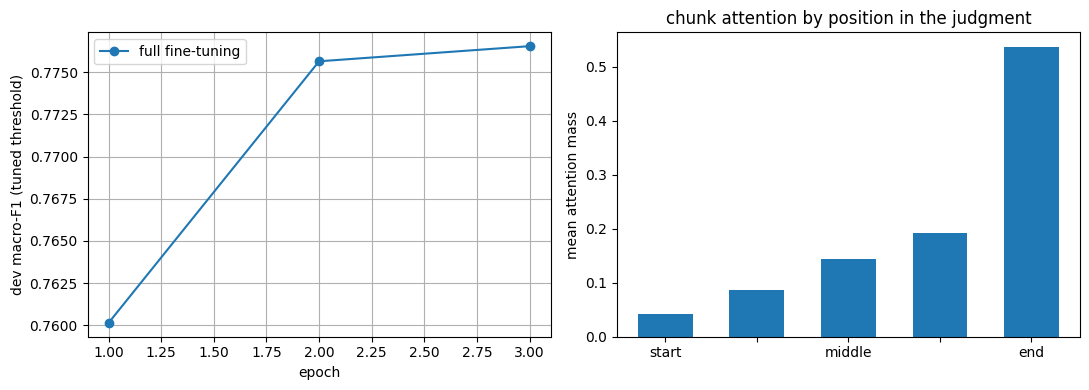

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

prof = profile_model(model, dev_loader, device)
r = results["full_ft"]
table = pd.DataFrame([{"model": "12L Phase 1 full fine-tuning", "dev macro-F1": r["macro_f1"], "precision": r["macro_precision"],
                       "recall": r["macro_recall"], "threshold": r["thr"], "params (M)": prof["params_M"],
                       "trained params (M)": r["trainable_params_M"], "fp16 size (MB)": prof["fp16_MB"],
                       "docs/s": prof["docs_per_sec"], "peak GPU (MB)": prof["peak_gpu_MB"]}]).round(4)
display(table)
table.to_csv(os.path.join(OUTPUT_DIR, "results_table_full_ft.csv"), index=False)
with open(os.path.join(OUTPUT_DIR, "results_full_ft.json"), "w") as f:
    json.dump(results, f, indent=2, default=float)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
if "history" in results:
    hist = results["history"]
    axes[0].plot([e["epoch"] for e in hist], [e["dev_f1_tuned"] for e in hist], marker="o", label="full fine-tuning")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("dev macro-F1 (tuned threshold)"); axes[0].legend(); axes[0].grid(True)

bins = ["start", "", "middle", "", "end"]
att = chunk_attention_profile(model, dev_loader, device)
axes[1].bar(np.arange(len(att)), att, 0.6)
axes[1].set_xticks(np.arange(len(att))); axes[1].set_xticklabels(bins); axes[1].set_ylabel("mean attention mass")
axes[1].set_title("chunk attention by position in the judgment")
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "phase4_curves_full_ft.png"), dpi=200); plt.show()

In [16]:
assert not SMOKE_TEST, "Set SMOKE_TEST = False and re-run the pipeline before making a real submission."

test_ids, test_probs, _ = predict_probs(model, test_loader, device)
test_preds = (test_probs >= thr).astype(int)

zip_path = write_submission(test_ids, test_preds, SUB_DIR, zip_name="submission_full_ft.zip")

wrote 1517 predictions -> /kaggle/working/cs781_phase4/submission/submission_full_ft.zip  (share of class 1: 0.486)
